In [ ]:
import numpy as np

rng = np.random.default_rng(seed=2026)
n = 10000

fraccion_eva = 0.5

if not 0 <= fraccion_eva <= 1:
    raise ValueError("fraccion_eva debe estar entre 0 y 1.")

bits_alice = rng.integers(0, 2, size=n)
bases_alice = rng.integers(0, 2, size=n)

bases_bob = rng.integers(0, 2, size=n)

intercepta = rng.random(n) < fraccion_eva

bases_eva = rng.integers(0, 2, size=n)
aleatorios_eva = rng.integers(0, 2, size=n)

bits_eva = np.where(
    bases_alice == bases_eva,
    bits_alice,
    aleatorios_eva
)

bits_recibidos = np.where(
    intercepta,
    bits_eva,
    bits_alice
)

bases_recibidas = np.where(
    intercepta,
    bases_eva,
    bases_alice
)

aleatorios_bob = rng.integers(0, 2, size=n)

bits_bob_con_eva = np.where(
    bases_bob == bases_recibidas,
    bits_recibidos,
    aleatorios_bob
)

coinciden = bases_alice == bases_bob

clave_alice = bits_alice[coinciden]
clave_bob_con_eva = bits_bob_con_eva[coinciden]

total_conservados = len(clave_alice)
total_interceptados = np.sum(intercepta)

errores_con_eva = np.sum(
    clave_alice != clave_bob_con_eva
)

print("Qubits enviados:", n)
print(f"Probabilidad de interceptación: {fraccion_eva * 100:.2f}%")
print("Qubits interceptados:", total_interceptados)

print("\nClave cribada de Alice:", clave_alice)
print("Clave cribada de Bob:  ", clave_bob_con_eva)

print("\nBits conservados:", total_conservados)
print("Errores:", errores_con_eva)

if total_conservados > 0:
    qber_con_eva = errores_con_eva / total_conservados
    print(f"QBER simulado: {qber_con_eva * 100:.2f}%")
else:
    print("No se conservaron bits; no se puede calcular el QBER.")

qber_esperado = fraccion_eva / 4
print(f"QBER teórico esperado: {qber_esperado * 100:.2f}%")


Qubits enviados: 10000
Probabilidad de interceptación: 50.00%
Qubits interceptados: 5076

Clave cribada de Alice: [1 0 0 ... 0 1 1]
Clave cribada de Bob:   [1 0 0 ... 0 1 1]

Bits conservados: 4932
Errores: 621
QBER simulado: 12.59%
QBER teórico esperado: 12.50%


Interceptación | QBER simulado | Intervalo Wilson 95%
           0% |         0.00% | [0.00%, 0.08%]
          10% |         2.33% | [1.94%, 2.79%]
          20% |         4.56% | [4.01%, 5.17%]
          30% |         7.24% | [6.55%, 7.99%]
          40% |        10.22% | [9.41%, 11.09%]
          50% |        12.78% | [11.89%, 13.73%]
          60% |        14.79% | [13.83%, 15.79%]
          70% |        16.88% | [15.87%, 17.93%]
          80% |        19.37% | [18.29%, 20.49%]
          90% |        21.87% | [20.76%, 23.03%]
         100% |        23.98% | [22.81%, 25.19%]


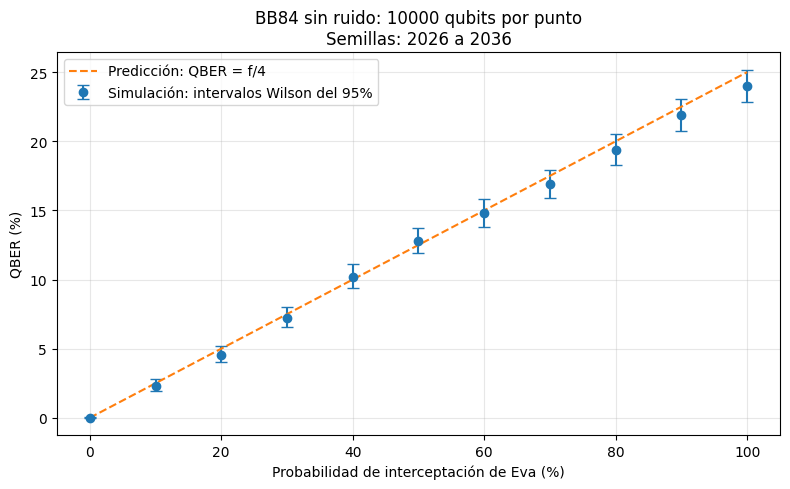

In [1]:
import numpy as np
import matplotlib.pyplot as plt


# 1. Simulación de BB84 con interceptación parcial.
def simular_qber(fraccion_eva, n, semilla):

    rng = np.random.default_rng(semilla)

    # Alice elige sus bits y bases.
    bits_alice = rng.integers(0, 2, size=n)
    bases_alice = rng.integers(0, 2, size=n)

    # Bob elige sus bases.
    bases_bob = rng.integers(0, 2, size=n)

    # Eva intercepta algunos qubits.
    intercepta = rng.random(n) < fraccion_eva

    bases_eva = rng.integers(0, 2, size=n)
    aleatorios_eva = rng.integers(0, 2, size=n)

    bits_eva = np.where(
        bases_alice == bases_eva,
        bits_alice,
        aleatorios_eva
    )

    # Estados que recibe Bob.
    bits_recibidos = np.where(
        intercepta,
        bits_eva,
        bits_alice
    )

    bases_recibidas = np.where(
        intercepta,
        bases_eva,
        bases_alice
    )

    # Mediciones de Bob.
    aleatorios_bob = rng.integers(0, 2, size=n)

    bits_bob = np.where(
        bases_bob == bases_recibidas,
        bits_recibidos,
        aleatorios_bob
    )

    # Cribado usando las bases de Alice y Bob.
    coinciden = bases_alice == bases_bob

    clave_alice = bits_alice[coinciden]
    clave_bob = bits_bob[coinciden]

    total_conservados = len(clave_alice)

    if total_conservados == 0:
        return np.nan, 0

    errores = np.sum(clave_alice != clave_bob)
    qber = errores / total_conservados

    return qber, total_conservados


# 2. Configuración de las pruebas.
n_grafica = 10000
semilla_inicial = 2026

fracciones = np.linspace(0, 1, 11)

qber_simulados = []
bits_conservados = []


# 3. Simulamos cada probabilidad de interceptación.
for i, fraccion in enumerate(fracciones):

    qber, cantidad = simular_qber(
        fraccion_eva=fraccion,
        n=n_grafica,
        semilla=semilla_inicial + i
    )

    qber_simulados.append(qber)
    bits_conservados.append(cantidad)

qber_simulados = np.array(qber_simulados)
bits_conservados = np.array(bits_conservados)


# 4. Intervalos de confianza Wilson al 95%.
q = qber_simulados
k = bits_conservados
z = 1.96

if np.any(k == 0):
    raise ValueError(
        "Alguna prueba no conservó bits. Aumenta n_grafica."
    )

denominador = 1 + z**2 / k

centro = (q + z**2 / (2 * k)) / denominador

margen = (
    z * np.sqrt(
        q * (1 - q) / k
        + z**2 / (4 * k**2)
    )
) / denominador

limite_inferior = np.clip(centro - margen, 0, 1)
limite_superior = np.clip(centro + margen, 0, 1)

# Longitud de las barras por debajo y por encima del punto.
barras = np.maximum(
    0,
    np.array([
        q - limite_inferior,
        limite_superior - q
    ])
)


# 5. Predicción teórica.
qber_teoricos = fracciones / 4


# 6. Tabla de resultados.
print("Interceptación | QBER simulado | Intervalo Wilson 95%")

for f, valor, inferior, superior in zip(
    fracciones,
    qber_simulados,
    limite_inferior,
    limite_superior
):
    print(
        f"{f * 100:>12.0f}% | "
        f"{valor * 100:>12.2f}% | "
        f"[{inferior * 100:.2f}%, {superior * 100:.2f}%]"
    )


# 7. Gráfica con barras de incertidumbre.
plt.figure(figsize=(8, 5))

plt.errorbar(
    fracciones * 100,
    qber_simulados * 100,
    yerr=barras * 100,
    fmt="o",
    capsize=4,
    label="Simulación: intervalos Wilson del 95%"
)

plt.plot(
    fracciones * 100,
    qber_teoricos * 100,
    "--",
    label="Predicción: QBER = f/4"
)

plt.xlabel("Probabilidad de interceptación de Eva (%)")
plt.ylabel("QBER (%)")

plt.title(
    f"BB84 sin ruido: {n_grafica} qubits por punto\n"
    f"Semillas: {semilla_inicial} a "
    f"{semilla_inicial + len(fracciones) - 1}"
)

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    "BB84_QBER_con_incertidumbre.png",
    dpi=300
)

plt.show()

Interceptación | Tasa cribada | Tasa secreta estimada
Tasas expresadas en bits por qubit enviado.

           0% |       0.4932 |               0.4932
          10% |       0.4939 |               0.3363
          20% |       0.4917 |               0.2289
          30% |       0.5000 |               0.1252
          40% |       0.4990 |               0.0240
          50% |       0.5015 |               0.0000
          60% |       0.5045 |               0.0000
          70% |       0.5084 |               0.0000
          80% |       0.4951 |               0.0000
          90% |       0.5089 |               0.0000
         100% |       0.4950 |               0.0000


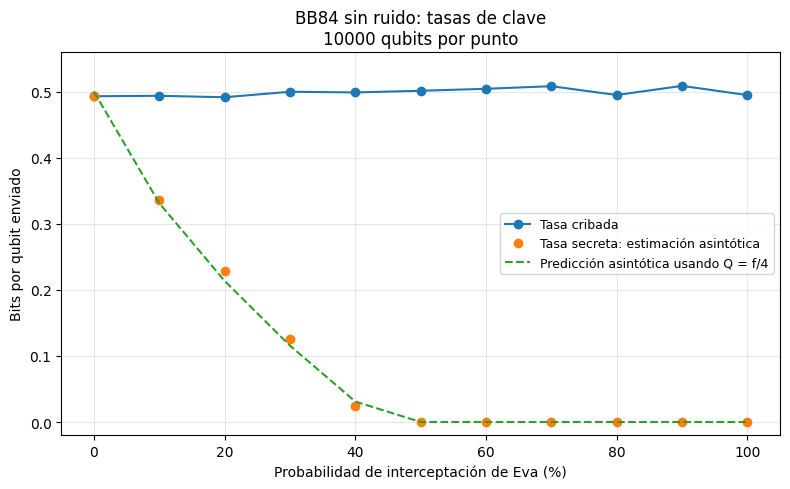

In [2]:

def entropia_binaria(q):

    q = np.asarray(q, dtype=float)
    h = np.zeros_like(q)

    interior = (q > 0) & (q < 1)
    p = q[interior]

    h[interior] = (
        -p * np.log2(p)
        -(1 - p) * np.log2(1 - p)
    )

    return h


tasa_cribada = bits_conservados / n_grafica

fraccion_secreta = np.maximum(
    0,
    1 - 2 * entropia_binaria(qber_simulados)
)

tasa_secreta = tasa_cribada * fraccion_secreta

tasa_secreta_teorica = 0.5 * np.maximum(
    0,
    1 - 2 * entropia_binaria(fracciones / 4)
)

print("Interceptación | Tasa cribada | Tasa secreta estimada")
print("Tasas expresadas en bits por qubit enviado.\n")

for f, cribada, secreta in zip(
    fracciones,
    tasa_cribada,
    tasa_secreta
):
    print(
        f"{f * 100:>12.0f}% | "
        f"{cribada:>12.4f} | "
        f"{secreta:>20.4f}"
    )

plt.figure(figsize=(8, 5))

plt.plot(
    fracciones * 100,
    tasa_cribada,
    "o-",
    label="Tasa cribada"
)

plt.plot(
    fracciones * 100,
    tasa_secreta,
    "o",
    label="Tasa secreta: estimación asintótica"
)

plt.plot(
    fracciones * 100,
    tasa_secreta_teorica,
    "--",
    label="Predicción asintótica usando Q = f/4"
)

plt.xlabel("Probabilidad de interceptación de Eva (%)")
plt.ylabel("Bits por qubit enviado")
plt.title(
    f"BB84 sin ruido: tasas de clave\n"
    f"{n_grafica} qubits por punto"
)

plt.ylim(-0.02, 0.56)
plt.grid(alpha=0.3)
plt.legend(fontsize=9)
plt.tight_layout()

plt.savefig("BB84_tasas_de_clave.png", dpi=300)
plt.show()